In [1]:
!pip install tensorflow-datasets matplotlib seaborn scikit-learn -q

import os, json, shutil, zipfile, time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from datetime import datetime

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (ModelCheckpoint, EarlyStopping,
                                         ReduceLROnPlateau, TensorBoard)
from tensorflow.keras.optimizers import Adam
import tensorflow_datasets as tfds

from sklearn.metrics import classification_report, confusion_matrix
from google.colab import files

print(f"✅ TensorFlow: {tf.__version__}")
print(f"✅ GPU available: {len(tf.config.list_physical_devices('GPU'))}")
print(f"✅ Device: {tf.test.gpu_device_name() or 'CPU'}")

✅ TensorFlow: 2.19.0
✅ GPU available: 1
✅ Device: /device:GPU:0


In [2]:
# ─── CONFIGURATION ─────────────────────────────────────────────────────────
# Choose dataset: 'food101' or 'indian_food'
DATASET = 'indian_food'  # <-- Change to 'indian_food' for Kaggle Indian Food dataset

# Image settings
IMG_SIZE    = 224      # MobileNetV2 input size
BATCH_SIZE  = 32
CHANNELS    = 3
INPUT_SHAPE = (IMG_SIZE, IMG_SIZE, CHANNELS)

# Training settings
EPOCHS_PHASE1 = 10    # Frozen base (fast ~20 min)
EPOCHS_PHASE2 = 15    # Fine-tuning (slower ~60 min)
LR_PHASE1     = 1e-3
LR_PHASE2     = 1e-5
FINE_TUNE_AT  = 100   # Unfreeze MobileNetV2 layers from this index onwards

# Paths
BASE_DIR   = Path('/content/fitai_model')
CKPT_DIR   = BASE_DIR / 'checkpoints'
EXPORT_DIR = BASE_DIR / 'export'
TFLITE_DIR = BASE_DIR / 'tflite'
LOG_DIR    = BASE_DIR / 'logs'

for d in [CKPT_DIR, EXPORT_DIR, TFLITE_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"📁 Dataset      : {DATASET}")
print(f"🖼️  Image size   : {IMG_SIZE}x{IMG_SIZE}")
print(f"📦 Batch size   : {BATCH_SIZE}")
print(f"🔁 Phase 1 epochs: {EPOCHS_PHASE1}")
print(f"🔁 Phase 2 epochs: {EPOCHS_PHASE2}")

📁 Dataset      : indian_food
🖼️  Image size   : 224x224
📦 Batch size   : 32
🔁 Phase 1 epochs: 10
🔁 Phase 2 epochs: 15


In [3]:
# ═══════════════════════════════════════════════════════════════════════════
# INSTRUCTIONS FOR INDIAN FOOD DATASET:
# 1. Go to: https://www.kaggle.com/datasets/iamsouravbanerjee/indian-food-images-dataset
# 2. Download the zip file
# 3. Upload it to Colab using files.upload() below
# 4. Set DATASET = 'indian_food' in Cell 1 config above
# ═══════════════════════════════════════════════════════════════════════════

if DATASET == 'indian_food':
    print("📤 Upload your Kaggle Indian Food dataset zip...")
    uploaded = files.upload()
    zip_name = list(uploaded.keys())[0]

    INDIAN_DATA = Path('/content/indian_food')
    INDIAN_DATA.mkdir(exist_ok=True)

    print(f"📦 Extracting {zip_name}...")
    with zipfile.ZipFile(zip_name, 'r') as z:
        z.extractall(INDIAN_DATA)

    # Find the actual data folder (folder containing class subfolders)
    data_root = None
    for d in sorted(INDIAN_DATA.rglob('*')):
        if d.is_dir():
            children = [c for c in d.iterdir() if c.is_dir()]
            if len(children) > 10:
                data_root = d
                break
    if data_root is None:
        data_root = INDIAN_DATA

    CLASS_NAMES_RAW = sorted([d.name for d in data_root.iterdir() if d.is_dir()])
    NUM_CLASSES = len(CLASS_NAMES_RAW)
    CLASS_NAMES = CLASS_NAMES_RAW

    print(f"\n✅ Found {NUM_CLASSES} food classes:")
    print(CLASS_NAMES[:10], '...')

    # Build train/val generators with augmentation
    train_datagen = ImageDataGenerator(
        preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
        validation_split=0.2,
        rotation_range=30,
        width_shift_range=0.15,
        height_shift_range=0.15,
        zoom_range=0.15,
        horizontal_flip=True,
        brightness_range=[0.8, 1.2]
    )

    train_gen = train_datagen.flow_from_directory(
        data_root, target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE, class_mode='sparse', subset='training'
    )
    val_gen = train_datagen.flow_from_directory(
        data_root, target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE, class_mode='sparse', subset='validation'
    )

    NUM_TRAIN = train_gen.samples
    NUM_VAL   = val_gen.samples

    # Save class names in generator index order
    CLASS_NAMES = [k for k, v in sorted(train_gen.class_indices.items(), key=lambda x: x[1])]
    with open(BASE_DIR / 'class_names.json', 'w') as f:
        json.dump(CLASS_NAMES, f, indent=2)

    print(f"\n🏋️ Train: {NUM_TRAIN} | Val: {NUM_VAL}")
    print(f"💾 Saved class_names.json")
    USING_GENERATOR = True
else:
    USING_GENERATOR = False

📤 Upload your Kaggle Indian Food dataset zip...


Saving Indian Food Images.zip to Indian Food Images.zip
📦 Extracting Indian Food Images.zip...

✅ Found 80 food classes:
['adhirasam', 'aloo_gobi', 'aloo_matar', 'aloo_methi', 'aloo_shimla_mirch', 'aloo_tikki', 'anarsa', 'ariselu', 'bandar_laddu', 'basundi'] ...
Found 3200 images belonging to 80 classes.
Found 800 images belonging to 80 classes.

🏋️ Train: 3200 | Val: 800
💾 Saved class_names.json


In [4]:
if DATASET == 'indian_food':
    from tensorflow.keras.preprocessing.image import ImageDataGenerator

    # ── Augmentation for training ──────────────────────────────────────────
    train_datagen = ImageDataGenerator(
        preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
        validation_split=0.2,       # 80% train, 20% val
        rotation_range=30,
        width_shift_range=0.15,
        height_shift_range=0.15,
        zoom_range=0.15,
        horizontal_flip=True,
        brightness_range=[0.8, 1.2],
        shear_range=0.1
    )

    # ── Validation uses only preprocessing (no augmentation) ──────────────
    val_datagen = ImageDataGenerator(
        preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
        validation_split=0.2
    )

    train_gen = train_datagen.flow_from_directory(
        data_root,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='sparse',
        subset='training',
        shuffle=True,
        seed=42
    )

    val_gen = val_datagen.flow_from_directory(
        data_root,
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='sparse',
        subset='validation',
        shuffle=False,
        seed=42
    )

    NUM_TRAIN = train_gen.samples
    NUM_VAL   = val_gen.samples

    # ── Save class names in generator index order ──────────────────────────
    # IMPORTANT: generator may reorder classes alphabetically
    # Always use this order — must match what model was trained on
    CLASS_NAMES = [k for k, v in sorted(train_gen.class_indices.items(), key=lambda x: x[1])]
    NUM_CLASSES = len(CLASS_NAMES)

    # Overwrite class_names.json with generator order
    with open(BASE_DIR / 'class_names.json', 'w') as f:
        json.dump(CLASS_NAMES, f, indent=2)

    STEPS_PER_EPOCH = NUM_TRAIN // BATCH_SIZE
    VAL_STEPS       = NUM_VAL   // BATCH_SIZE
    USING_GENERATOR = True

    print("✅ Data generators ready!")
    print(f"   Train samples : {NUM_TRAIN:,}")
    print(f"   Val samples   : {NUM_VAL:,}")
    print(f"   Classes       : {NUM_CLASSES}")
    print(f"   Steps/epoch   : {STEPS_PER_EPOCH}")
    print(f"   Val steps     : {VAL_STEPS}")
    print(f"\n📋 Class index mapping (first 10):")
    for cls, idx in list(train_gen.class_indices.items())[:10]:
        print(f"   {idx:>3}: {cls}")

elif DATASET == 'food101':
    AUTOTUNE = tf.data.AUTOTUNE

    def preprocess(image, label):
        image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
        image = tf.cast(image, tf.float32)
        image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
        return image, label

    def augment(image, label):
        image, label = preprocess(image, label)
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_brightness(image, max_delta=0.2)
        image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
        image = tf.image.random_saturation(image, lower=0.8, upper=1.2)
        image = tf.image.random_crop(
            tf.image.resize_with_crop_or_pad(image, IMG_SIZE + 30, IMG_SIZE + 30),
            size=[IMG_SIZE, IMG_SIZE, CHANNELS]
        )
        return image, label

    train_ds = (
        ds_train_raw
        .shuffle(5000, reshuffle_each_iteration=True)
        .map(augment, num_parallel_calls=AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )
    val_ds = (
        ds_val_raw
        .map(preprocess, num_parallel_calls=AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

    STEPS_PER_EPOCH = NUM_TRAIN // BATCH_SIZE
    VAL_STEPS       = NUM_VAL   // BATCH_SIZE
    USING_GENERATOR = False
    print(f"✅ Pipeline ready | Steps/epoch: {STEPS_PER_EPOCH} | Val steps: {VAL_STEPS}")

Found 3200 images belonging to 80 classes.
Found 800 images belonging to 80 classes.
✅ Data generators ready!
   Train samples : 3,200
   Val samples   : 800
   Classes       : 80
   Steps/epoch   : 100
   Val steps     : 25

📋 Class index mapping (first 10):
     0: adhirasam
     1: aloo_gobi
     2: aloo_matar
     3: aloo_methi
     4: aloo_shimla_mirch
     5: aloo_tikki
     6: anarsa
     7: ariselu
     8: bandar_laddu
     9: basundi


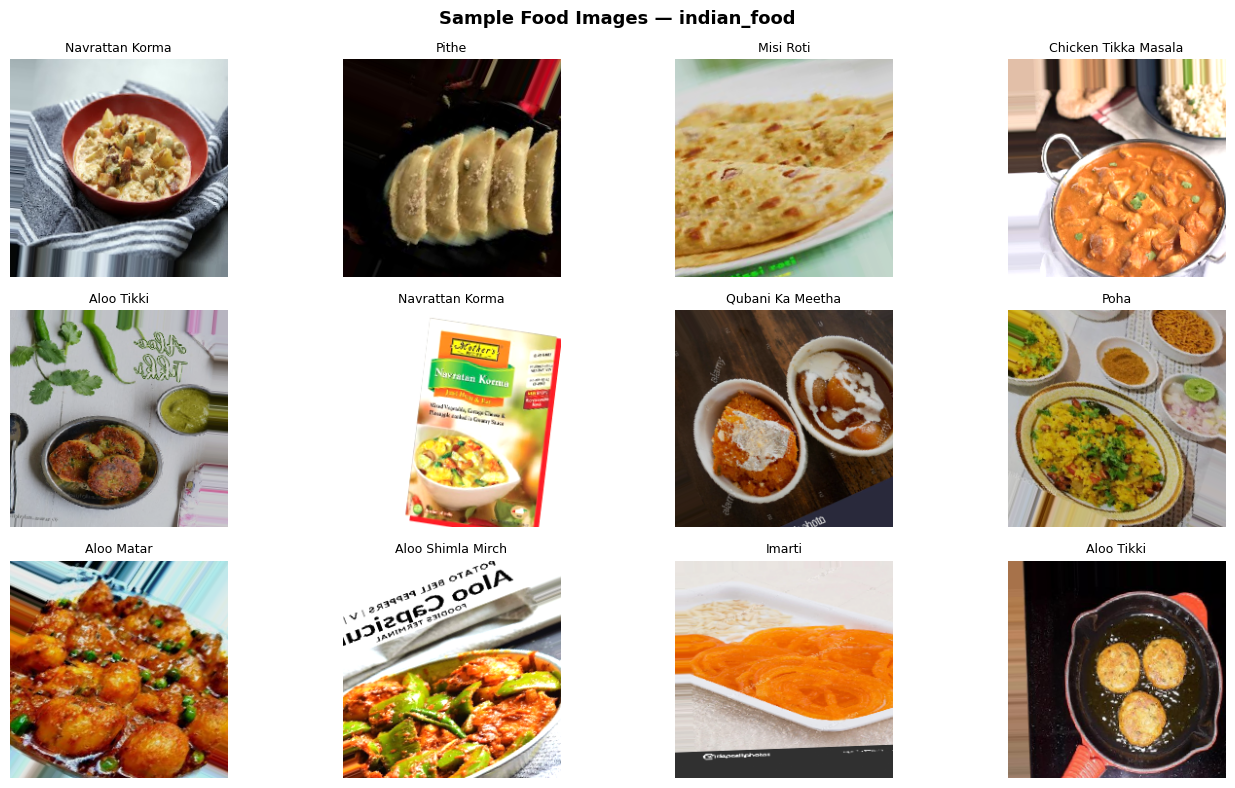

💾 Saved sample_images.png


In [5]:
plt.figure(figsize=(14, 8))

if DATASET == 'food101':
    sample_batch = next(iter(ds_train_raw.shuffle(1000).take(12).batch(12)))
    images, labels = sample_batch
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        img = tf.image.resize(images[i], [224, 224]).numpy().astype('uint8')
        plt.imshow(img)
        plt.title(CLASS_NAMES[labels[i].numpy()].replace('_', ' ').title(), fontsize=9)
        plt.axis('off')

elif DATASET == 'indian_food' and USING_GENERATOR:
    batch_imgs, batch_lbls = next(train_gen)
    for i in range(min(12, len(batch_imgs))):
        plt.subplot(3, 4, i + 1)
        img = (batch_imgs[i] + 1) / 2   # [-1,1] → [0,1]
        plt.imshow(np.clip(img, 0, 1))
        plt.title(CLASS_NAMES[int(batch_lbls[i])].replace('_', ' ').title(), fontsize=9)
        plt.axis('off')

plt.suptitle(f'Sample Food Images — {DATASET}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(BASE_DIR / 'sample_images.png', dpi=120, bbox_inches='tight')
plt.show()
print("💾 Saved sample_images.png")

In [6]:
def build_model(num_classes, input_shape=INPUT_SHAPE, fine_tune=False, fine_tune_at=FINE_TUNE_AT):
    """
    MobileNetV2 Transfer Learning Architecture:

    Input (224x224x3)
         ↓
    MobileNetV2 base (ImageNet pretrained, frozen or partially unfrozen)
         ↓
    GlobalAveragePooling2D
         ↓
    BatchNormalization
         ↓
    Dense(512, relu) + Dropout(0.3)
         ↓
    Dense(256, relu) + Dropout(0.2)
         ↓
    Dense(num_classes, softmax)
    """
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )

    if fine_tune:
        base_model.trainable = True
        for layer in base_model.layers[:fine_tune_at]:
            layer.trainable = False
        trainable = sum(1 for l in base_model.layers if l.trainable)
        print(f"🔓 Fine-tuning: layers {fine_tune_at}–{len(base_model.layers)} trainable")
        print(f"   Trainable base layers: {trainable}/{len(base_model.layers)}")
    else:
        base_model.trainable = False
        print(f"🔒 Phase 1: Base frozen ({len(base_model.layers)} layers)")

    inputs  = keras.Input(shape=input_shape, name='input_image')
    x       = base_model(inputs, training=fine_tune)
    x       = layers.GlobalAveragePooling2D(name='global_avg_pool')(x)
    x       = layers.BatchNormalization(name='batch_norm')(x)
    x       = layers.Dense(512, activation='relu', name='dense_512',
                           kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x       = layers.Dropout(0.3, name='dropout_1')(x)
    x       = layers.Dense(256, activation='relu', name='dense_256',
                           kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x       = layers.Dropout(0.2, name='dropout_2')(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = Model(inputs, outputs, name='FitAI_FoodClassifier')
    return model, base_model


# Build Phase 1 model (frozen base)
model, base_model = build_model(NUM_CLASSES, fine_tune=False)

model.compile(
    optimizer=Adam(learning_rate=LR_PHASE1),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5_acc')]
)

model.summary()
print(f"\n📊 Total params    : {model.count_params():,}")
print(f"📊 Trainable params: {sum([np.prod(v.shape) for v in model.trainable_variables]):,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
🔒 Phase 1: Base frozen (154 layers)


Model: "FitAI_FoodClassifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_512 (Dense)               │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 80)             │        20,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,070,864 (11.71 MB)

 Trainable params: 810,320 (3.09 MB)

 Non-trainable params: 2,260,544 (8.62 MB)


📊 Total params    : 3,070,864
📊 Trainable params: 810,320


In [7]:
callbacks_p1 = [
    ModelCheckpoint(
        filepath=str(CKPT_DIR / 'phase1_best.keras'),
        save_best_only=True,
        monitor='val_accuracy',
        mode='max',
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    TensorBoard(log_dir=str(LOG_DIR / 'phase1'), histogram_freq=0)
]

print("=" * 55)
print("  🚀 PHASE 1: Training classification head (frozen base)")
print("=" * 55)
start = time.time()

if DATASET == 'food101':
    history_p1 = model.fit(
        train_ds,
        epochs=EPOCHS_PHASE1,
        validation_data=val_ds,
        callbacks=callbacks_p1,
        steps_per_epoch=STEPS_PER_EPOCH,
        validation_steps=VAL_STEPS
    )
else:
    history_p1 = model.fit(
        train_gen,
        epochs=EPOCHS_PHASE1,
        validation_data=val_gen,
        callbacks=callbacks_p1
    )

elapsed = time.time() - start
print(f"\n⏱️ Phase 1 done in {elapsed/60:.1f} min")
print(f"✅ Best val accuracy: {max(history_p1.history['val_accuracy']):.4f}")

  🚀 PHASE 1: Training classification head (frozen base)


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.0718 - loss: 4.4185 - top5_acc: 0.2043
Epoch 1: val_accuracy improved from -inf to 0.33750, saving model to /content/fitai_model/checkpoints/phase1_best.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 81s 606ms/step - accuracy: 0.0724 - loss: 4.4136 - top5_acc: 0.2056 - val_accuracy: 0.3375 - val_loss: 2.8781 - val_top5_acc: 0.6925 - learning_rate: 0.0010
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.3479 - loss: 2.6204 - top5_acc: 0.6732
Epoch 2: val_accuracy improved from 0.33750 to 0.45750, saving model to /content/fitai_model/checkpoints/phase1_best.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 54s 540ms/step - accuracy: 0.3481 - loss: 2.6201 - top5_acc: 0.6733 - val_accuracy: 0.4575 - val_loss: 2.1887 - val_top5_acc: 0.7812 - learning_rate: 0.0010
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - accuracy: 0.4834 - loss: 2.0407 - top5_acc: 0.7869
Epoch 3: val_accuracy improved from 0.45750 to 0.51625, saving m

In [8]:
print("=" * 55)
print(f"  🔬 PHASE 2: Fine-tuning (unfreezing from layer {FINE_TUNE_AT})")
print("=" * 55)

# Load best Phase 1 weights
model.load_weights(str(CKPT_DIR / 'phase1_best.keras'))

# Unfreeze top layers of base
base_model.trainable = True
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

# Recompile with much lower learning rate
model.compile(
    optimizer=Adam(learning_rate=LR_PHASE2),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5_acc')]
)

trainable_layers = sum(1 for l in base_model.layers if l.trainable)
print(f"🔓 Unfrozen base layers: {trainable_layers}")
print(f"📊 Trainable params: {sum([np.prod(v.shape) for v in model.trainable_variables]):,}")

callbacks_p2 = [
    ModelCheckpoint(
        filepath=str(CKPT_DIR / 'phase2_best.keras'),
        save_best_only=True,
        monitor='val_accuracy',
        mode='max',
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=3,
        min_lr=1e-8,
        verbose=1
    ),
    TensorBoard(log_dir=str(LOG_DIR / 'phase2'), histogram_freq=0)
]

start = time.time()

if DATASET == 'food101':
    history_p2 = model.fit(
        train_ds,
        epochs=EPOCHS_PHASE2,
        validation_data=val_ds,
        callbacks=callbacks_p2,
        steps_per_epoch=STEPS_PER_EPOCH,
        validation_steps=VAL_STEPS
    )
else:
    history_p2 = model.fit(
        train_gen,
        epochs=EPOCHS_PHASE2,
        validation_data=val_gen,
        callbacks=callbacks_p2
    )

elapsed = time.time() - start
print(f"\n⏱️ Phase 2 done in {elapsed/60:.1f} min")
print(f"✅ Best val accuracy: {max(history_p2.history['val_accuracy']):.4f}")

  🔬 PHASE 2: Fine-tuning (unfreezing from layer 100)
🔓 Unfrozen base layers: 54
📊 Trainable params: 2,671,760
Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - accuracy: 0.4911 - loss: 2.0088 - top5_acc: 0.8100
Epoch 1: val_accuracy improved from -inf to 0.55750, saving model to /content/fitai_model/checkpoints/phase2_best.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 83s 591ms/step - accuracy: 0.4912 - loss: 2.0081 - top5_acc: 0.8102 - val_accuracy: 0.5575 - val_loss: 2.0041 - val_top5_acc: 0.8300 - learning_rate: 1.0000e-05
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.5519 - loss: 1.7116 - top5_acc: 0.8539
Epoch 2: val_accuracy did not improve from 0.55750
100/100 ━━━━━━━━━━━━━━━━━━━━ 54s 536ms/step - accuracy: 0.5521 - loss: 1.7112 - top5_acc: 0.8540 - val_accuracy: 0.5400 - val_loss: 2.1045 - val_top5_acc: 0.8163 - learning_rate: 1.0000e-05
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.5949 - loss: 1.5671 - top5_acc: 0.8820
Epoch 3: val_accur

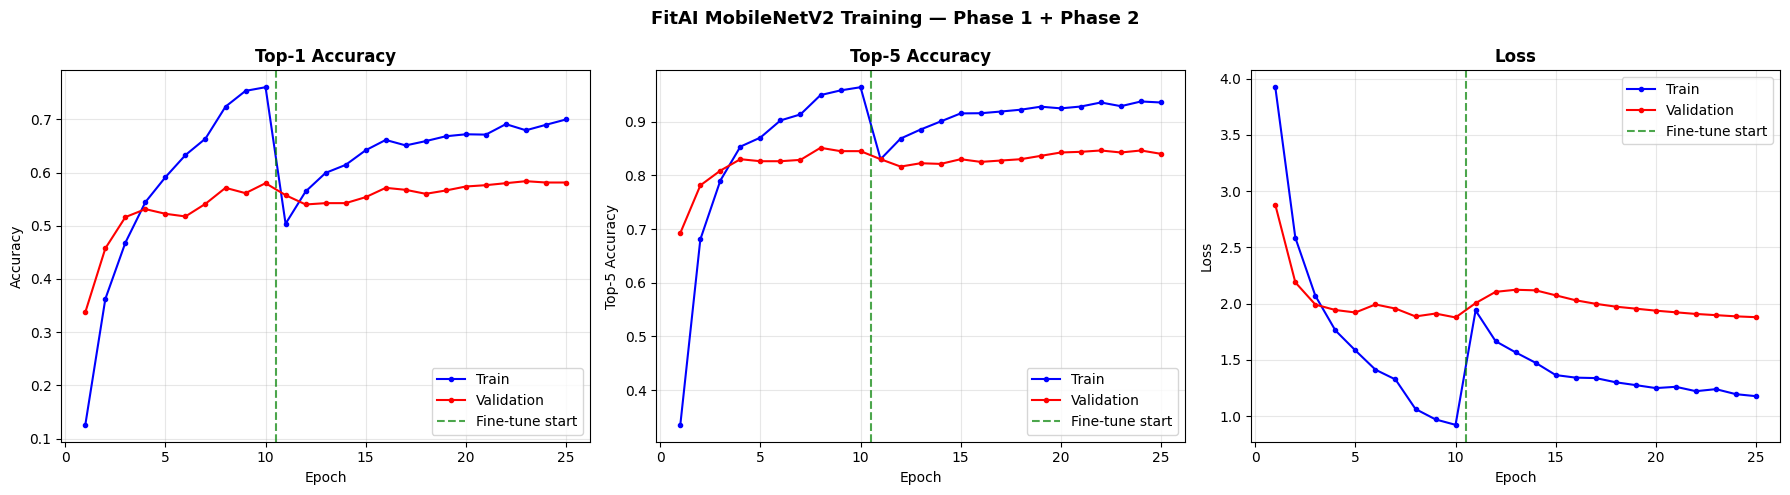


──────────────────────────────────────────────────
  Metric                       Phase 1    Phase 2
──────────────────────────────────────────────────
  Best Val Accuracy             0.5800     0.5838
  Best Val Top-5 Acc            0.8512     0.8462
  Final Val Loss                1.8767     1.8792
──────────────────────────────────────────────────
💾 Saved training_history.png


In [9]:
def plot_training_history(h1, h2):
    def combine(key):
        return h1.history.get(key, []) + h2.history.get(key, [])

    acc      = combine('accuracy')
    val_acc  = combine('val_accuracy')
    loss     = combine('loss')
    val_loss = combine('val_loss')
    top5     = combine('top5_acc')
    val_top5 = combine('val_top5_acc')
    ep1_end  = len(h1.history['accuracy'])

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    epochs_range = range(1, len(acc) + 1)

    for ax, (train_m, val_m, title, ylabel) in zip(
        axes,
        [
            (acc,  val_acc,  'Top-1 Accuracy', 'Accuracy'),
            (top5, val_top5, 'Top-5 Accuracy', 'Top-5 Accuracy'),
            (loss, val_loss, 'Loss',            'Loss'),
        ]
    ):
        ax.plot(epochs_range, train_m, 'b-o', markersize=3, label='Train')
        ax.plot(epochs_range, val_m,   'r-o', markersize=3, label='Validation')
        ax.axvline(x=ep1_end + 0.5, color='green', linestyle='--', alpha=0.7, label='Fine-tune start')
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(ylabel)
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.suptitle('FitAI MobileNetV2 Training — Phase 1 + Phase 2', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(BASE_DIR / 'training_history.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("\n" + "─" * 50)
    print(f"  {'Metric':<25} {'Phase 1':>10} {'Phase 2':>10}")
    print("─" * 50)
    print(f"  {'Best Val Accuracy':<25} {max(h1.history['val_accuracy']):>10.4f} {max(h2.history['val_accuracy']):>10.4f}")
    print(f"  {'Best Val Top-5 Acc':<25} {max(h1.history['val_top5_acc']):>10.4f} {max(h2.history['val_top5_acc']):>10.4f}")
    print(f"  {'Final Val Loss':<25} {h1.history['val_loss'][-1]:>10.4f} {h2.history['val_loss'][-1]:>10.4f}")
    print("─" * 50)

plot_training_history(history_p1, history_p2)
print("💾 Saved training_history.png")

In [10]:
# Load best Phase 2 weights
model.load_weights(str(CKPT_DIR / 'phase2_best.keras'))

print("🧪 Evaluating on validation set...")

if DATASET == 'food101':
    results = model.evaluate(val_ds, steps=VAL_STEPS, verbose=1)
else:
    results = model.evaluate(val_gen, verbose=1)

print(f"\n📊 Final Results:")
print(f"   Loss      : {results[0]:.4f}")
print(f"   Top-1 Acc : {results[1]*100:.2f}%")
print(f"   Top-5 Acc : {results[2]*100:.2f}%")

🧪 Evaluating on validation set...
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 160ms/step - accuracy: 0.5682 - loss: 1.8745 - top5_acc: 0.8336

📊 Final Results:
   Loss      : 1.8973
   Top-1 Acc : 58.38%
   Top-5 Acc : 84.25%


In [11]:
# ── 9A: Keras format ──────────────────────────────────────────────────────
keras_path = str(EXPORT_DIR / 'food_classifier.keras')
model.save(keras_path)
print(f"✅ Keras model saved: {keras_path}")

# ── 9B: SavedModel format ─────────────────────────────────────────────────
saved_model_path = str(EXPORT_DIR / 'saved_model')
model.export(saved_model_path)
print(f"✅ SavedModel saved: {saved_model_path}")

# ── 9C: TFLite float32 ───────────────────────────────────────────────────
print("\n🔄 Converting to TFLite (float32)...")
converter    = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
tflite_path  = TFLITE_DIR / 'food_classifier.tflite'
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)
print(f"✅ TFLite (float32): {os.path.getsize(tflite_path)/(1024*1024):.1f} MB")

# ── 9D: TFLite INT8 quantized ─────────────────────────────────────────────
print("\n🔄 Converting to TFLite (INT8 quantized)...")
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]

if DATASET == 'food101':
    def representative_data_gen():
        for imgs, _ in ds_val_raw.shuffle(500).take(100).batch(1):
            imgs = tf.image.resize(imgs, [IMG_SIZE, IMG_SIZE])
            imgs = tf.cast(imgs, tf.float32)
            imgs = tf.keras.applications.mobilenet_v2.preprocess_input(imgs)
            yield [imgs]
    converter_q.representative_dataset = representative_data_gen

converter_q.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_q.inference_input_type      = tf.uint8
converter_q.inference_output_type     = tf.uint8

try:
    tflite_q      = converter_q.convert()
    tflite_q_path = TFLITE_DIR / 'food_classifier_int8.tflite'
    with open(tflite_q_path, 'wb') as f:
        f.write(tflite_q)
    print(f"✅ TFLite (INT8): {os.path.getsize(tflite_q_path)/(1024*1024):.1f} MB")
except Exception as e:
    print(f"⚠️ INT8 quantization failed ({e}), float32 only")

# ── 9E: Save metadata ─────────────────────────────────────────────────────
metadata = {
    'dataset'            : DATASET,
    'num_classes'        : NUM_CLASSES,
    'class_names'        : CLASS_NAMES,
    'img_size'           : IMG_SIZE,
    'model_architecture' : 'MobileNetV2',
    'fine_tune_at'       : FINE_TUNE_AT,
    'best_val_accuracy'  : float(max(history_p2.history['val_accuracy'])),
    'best_val_top5'      : float(max(history_p2.history['val_top5_acc'])),
    'trained_at'         : datetime.now().isoformat(),
    'preprocessing'      : 'mobilenet_v2.preprocess_input  # scales to [-1, 1]'
}
with open(BASE_DIR / 'model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print(f"\n✅ Metadata saved")
print(f"   Val Acc  : {metadata['best_val_accuracy']*100:.2f}%")
print(f"   Val Top5 : {metadata['best_val_top5']*100:.2f}%")

✅ Keras model saved: /content/fitai_model/export/food_classifier.keras
Saved artifact at '/content/fitai_model/export/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 80), dtype=tf.float32, name=None)
Captures:
  136192991693904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136192991695056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136192991695440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136192991694672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136192991693712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136192991695248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136192991695632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136192991696400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136192991696016: TensorSpec(shape=(), dtype=tf.resource, nam

In [12]:
files.download(keras_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>